# Zero-Shot Chest Pathology Classification with MedImageInsight

Compare chest X-ray embeddings with five text descriptions to classify the sample images without training a classifier. This notebook supports MedImageInsight and MedImageInsight Premium through the Healthcare AI Toolkit client factory.

The five categories are No Finding, Support Devices, Pleural Effusion, Cardiomegaly, and Atelectasis. Scaled image-text similarities are converted to softmax scores, and the highest-scoring description determines the predicted class.

## Prerequisites

Follow the [repository setup instructions](../../README.md) to install the toolkit, download the sample data, and configure your `.env` file.

- Set `DATA_ROOT` to the directory containing `medimageinsight-classification`.
- Set `MI2_PREMIUM_ENDPOINT` or `MI2_MODEL_ENDPOINT` for your deployed model.

For a direct URL (including Foundry), also set the matching `MI2_PREMIUM_API_KEY` or `MI2_MODEL_API_KEY`. For an Azure ML endpoint ID or name, the client can retrieve the key using your Azure credentials if you have permission.

## Workflow

1. Generate embeddings for 100 DICOM images and the five text descriptions.
2. Compute scaled similarities and class scores.
3. Evaluate against the labels and inspect example predictions.
4. Export `zero_shot_classification_results.csv` for comparison in the [adapter-training notebook](./adapter-training.ipynb).

The sample assigns one label per image. It is a workflow demonstration, not a validated clinical classifier.

## 1. Setup and Imports

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sitk.ProcessObject_SetGlobalWarningDisplay(False)

### Select the Model Client

`get_medimage_client` is a helper for these example notebooks that creates a client from your configured endpoints. It selects Premium when configured, otherwise open-source, and raises an error if neither is configured.

Set `variant="premium"` or `variant="opensource"` to choose explicitly.

In [3]:
## Parameters

variant = None

In [4]:
from healthcareai_toolkit.clients import get_medimage_client

mi2_client = get_medimage_client("mi2", variant=variant)
print(mi2_client)
submitter = mi2_client.create_submitter()

MedImageInsightPremiumClient(
    target='https://<account>.services.ai.azure.com/providers/microsoft/v2/embed',
    deployment_name='MedImageInsight-Premium',
    image_reader='sitk',
    resize_size=(480, 480)
)


### Input Data

The sample contains 100 DICOM images: 20 each for No Finding, Support Devices, Pleural Effusion, Cardiomegaly, and Atelectasis. The toolkit reads and preprocesses the images before sending them to the endpoint.

The five descriptions in `chest_pathology_text` name the modality, body region, view, and finding. Their order matches the numeric labels in the sample CSV. Keep that mapping consistent if you change the descriptions or add classes.

In [2]:
from healthcareai_toolkit import settings

## Input Images and Text for Inference
data_root = settings.DATA_ROOT

if not os.path.exists(data_root):
    raise (
        Exception(
            f"Please download the files as described in this notebook into the data_root: {data_root}"
        )
    )

## Load image input folder for generating image embeddings
input_folder = os.path.join(data_root, "medimageinsight-classification", "images")
## Load csv folder labels and splits
csv_folder = os.path.join(data_root, "medimageinsight-classification", "csv")

## For Text
## You can add your own text or use the below text for inference
chest_pathology_text = [
    "x-ray chest anteroposterior No Finding",
    "x-ray chest anteroposterior Support Devices",
    "x-ray chest anteroposterior Pleural Effusion",
    "x-ray chest anteroposterior Cardiomegaly",
    "x-ray chest anteroposterior Atelectasis",
]

## 2. Compute Zero-Shot Class Scores

Generate text and image embeddings using the same model, compute their scaled dot products, and apply softmax across the five descriptions. The next sections separate these steps so you can inspect the feature and score shapes.

### 2.1. Compute Embeddings

Use the client and submitter created in Section 1 to obtain image and text embeddings in separate requests. The submitter's default batch size of one also matches the Premium client's single-input request format.

These cells call your configured endpoint. The remaining scoring and evaluation steps run locally on the returned embeddings.

In [5]:
import glob

image_files = list(glob.glob(input_folder + "/*.dcm"))

_, text_results = submitter.submit(
    text_list=chest_pathology_text, total=len(chest_pathology_text)
)
_, image_results = submitter.submit(image_list=image_files, total=len(image_files))

100%|██████████| 100/100 [00:26<00:00,  3.84it/s]


In [ ]:
from healthcareai_toolkit.clients import MedImageInsightPremiumClient

name_list = [os.path.basename(f) for f in image_files]

image_features = np.stack(
    [np.squeeze(np.array(v["image_features"])) for v in image_results]
)
text_features = np.stack(
    [np.squeeze(np.array(v["text_features"])) for v in text_results]
)
scaling_factor = image_results[0].get("scaling_factor")
if scaling_factor is None and isinstance(mi2_client, MedImageInsightPremiumClient):
    # Workaround for missing Premium base-model log scale (Bug 3055661).
    # Fine-tuned models will have a different value.
    scaling_factor = 4.486177921295166
if scaling_factor is None:
    raise ValueError("The endpoint did not return scaling_factor.")
scaling_factor = np.atleast_1d(scaling_factor)

print(image_features.shape, text_features.shape, scaling_factor.shape)

(100, 1024) (5, 1024) (1,)


### 2.2. Calculate Image-Text Similarity

Take the dot product of the normalized image and text embeddings to obtain one similarity per image and class. Multiply those similarities by the learned scale, then apply softmax in the next step. The dot product alone is not a probability.

This notebook uses `scaling_factor` in natural-log units. Apply `exp()` exactly once. The science-confirmed Premium base-model value is approximately 4.486178, giving a multiplier of approximately 88.7815. Multiplying by this positive value changes the softmax scores but not the highest-scoring class.

**Premium limitation:** the notebook temporarily supplies the base-model value when the response value is missing or `None` and the client is Premium. Fine-tuned models will have a different value; use the scale for the deployed model.

In [7]:
## Perform zero-Shot classification across all images in the folder
logits_per_image = (
    torch.from_numpy(scaling_factor).exp()
    * torch.from_numpy((np.array(image_features)))
    @ torch.from_numpy(np.array(text_features)).t()
)
print(logits_per_image.shape)

torch.Size([100, 5])


### 2.3. Convert Similarities to Class Scores

Apply softmax across the five text descriptions so each image's scores sum to one. The highest-scoring description is the predicted class. These relative scores depend on the label set and are not calibrated disease probabilities.

In [8]:
probs = logits_per_image.softmax(dim=-1).cpu().numpy()
print(probs.shape)

(100, 5)


## 3. Evaluate Zero-Shot Predictions

Join each prediction to `dcm_sample_label.csv` by image name. The classification report shows precision, recall, F1-score, and accuracy; the confusion matrix shows the number of predictions for each true/predicted class pair.

This section evaluates all 100 sample images. The adapter notebook reports on the 20-image test split, so the overall scores from the two reports are not a direct comparison unless both are evaluated on the same subset.

Zero-Shot Classification Report:
                   precision    recall  f1-score   support

      No Finding       0.31      0.55      0.39        20
 Support Devices       0.67      0.10      0.17        20
Pleural Effusion       0.93      0.70      0.80        20
    Cardiomegaly       0.63      0.60      0.62        20
     Atelectasis       0.52      0.70      0.60        20

        accuracy                           0.53       100
       macro avg       0.61      0.53      0.52       100
    weighted avg       0.61      0.53      0.52       100



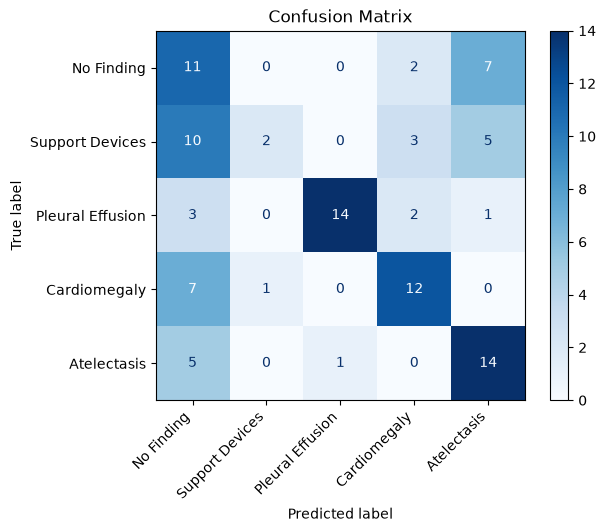

In [9]:
from sklearn.metrics import classification_report

findings_df = pd.read_csv(os.path.join(csv_folder, "dcm_sample_label.csv"))
predictions = pd.DataFrame(
    {"Name": name_list, "PredictedClass": probs.argmax(axis=1)}
).merge(
    findings_df[["Name", "Label", "Label Category"]],
    on="Name",
    how="left",
    validate="one_to_one",
)
label_category = (
    findings_df.drop_duplicates("Label")
    .set_index("Label")["Label Category"]
    .sort_index()
)
report = classification_report(
    predictions["Label"],
    predictions["PredictedClass"],
    labels=label_category.index,
    target_names=label_category.tolist(),
)
print("Zero-Shot Classification Report:\n", report)

cm = confusion_matrix(
    predictions["Label"], predictions["PredictedClass"], labels=label_category.index
)
disp = ConfusionMatrixDisplay(cm, display_labels=label_category.tolist())
disp.plot(cmap=plt.cm.Blues)
plt.xticks(rotation=45, ha="right")
plt.title("Confusion Matrix")
plt.show()

### Interpret the Results

Use the report and confusion matrix from your run to inspect class-level precision, recall, and errors. Results depend on the selected model, text descriptions, and sample images; the notebook does not assume fixed class-by-class scores.

The softmax scores compare only the five supplied descriptions. They are not calibrated probabilities of disease, and this single-label example does not represent cases with multiple findings.

The [adapter-training notebook](./adapter-training.ipynb) uses labeled embeddings to train a classifier. Compare both methods on the same evaluation images and with the same embedding model.

## 4. Export and Inspect Example Predictions

Save the predictions to `zero_shot_classification_results.csv` in the notebook's working directory. The adapter notebook reads this file for its comparison, so run both notebooks with the same model variant and working directory.

Display four fixed sample images with their predicted and reference labels. These examples are kept consistent across the notebooks; whether each prediction is correct depends on the run.

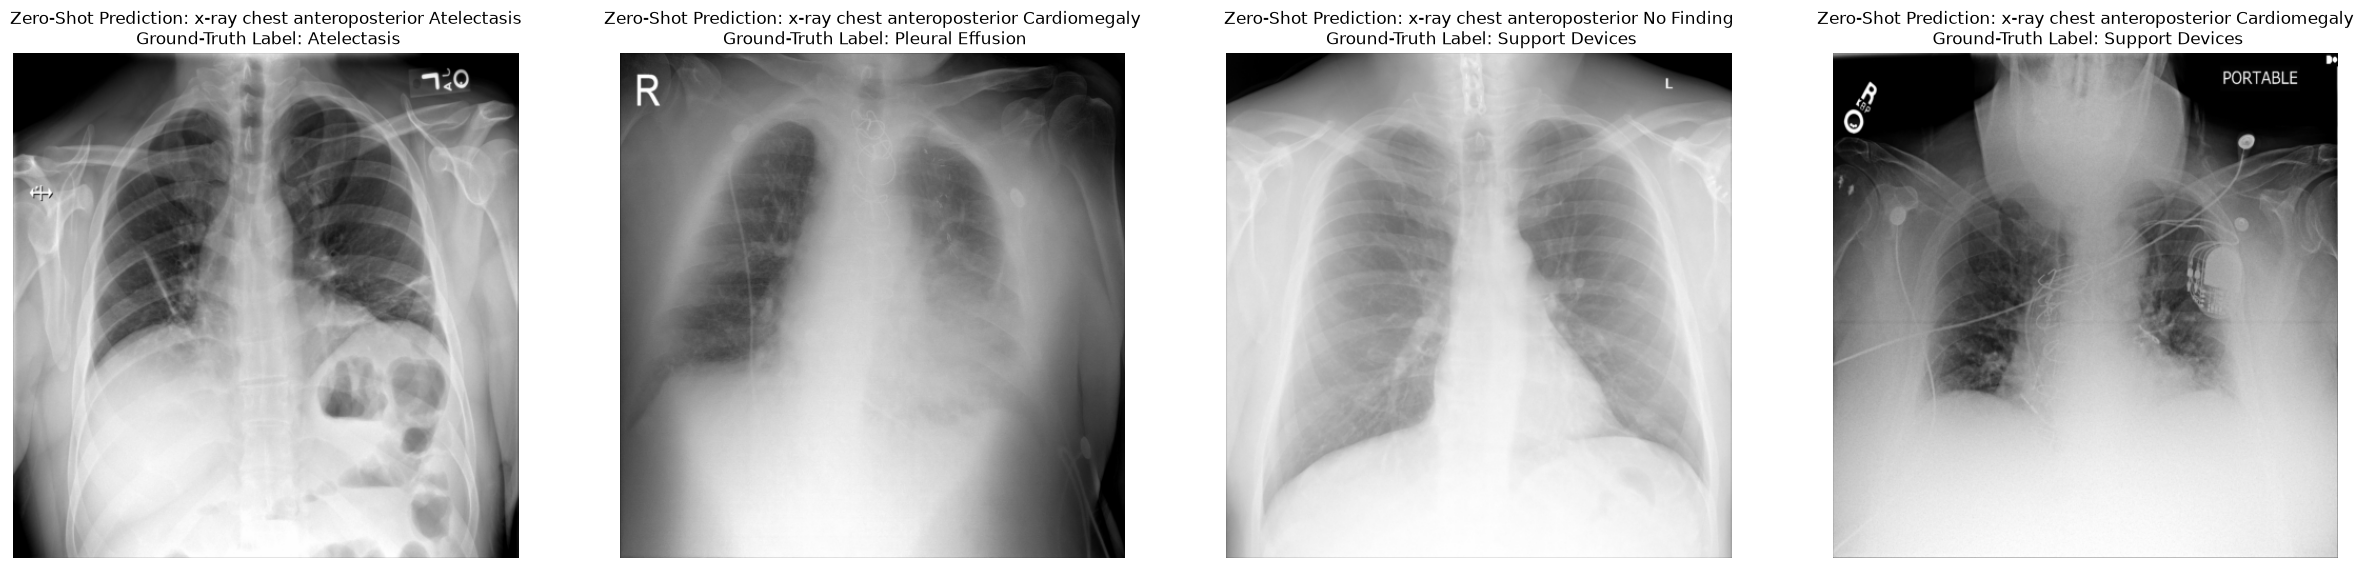

In [10]:
df = (
    predictions[["Name"]]
    .rename(columns={"Name": "file_name"})
    .assign(
        zero_shot_pred=predictions["PredictedClass"].map(
            pd.Series(chest_pathology_text)
        ),
        ground_truth_label=predictions["Label Category"],
    )
)
df.to_csv("./zero_shot_classification_results.csv", index=False)

selected_images = [
    "1.3.6.1.4.1.55648.013051327602219610100989737191708734008.2.1.green.dcm",
    "1.3.6.1.4.1.55648.045678110342520932233807899271374363433.1.1.green.dcm",
    "1.3.6.1.4.1.55648.255611619245397591591431066926543031128.1312.1.green.dcm",
    "1.3.6.1.4.1.55648.023647312006371870964474485493542161185.1.1.green.dcm",
]
selected_data = df.set_index("file_name").loc[selected_images]

fig, axs = plt.subplots(1, 4, figsize=(30, 10))
for axis, (image_name, row) in zip(axs, selected_data.iterrows()):
    image_path = os.path.join(input_folder, image_name)
    image = mi2_client.read_and_normalize_image(image_path)
    axis.imshow(image, cmap="bone")
    axis.axis("off")
    axis.set_title(
        "Zero-Shot Prediction: {}\n Ground-Truth Label: {}".format(
            row["zero_shot_pred"], row["ground_truth_label"]
        )
    )

plt.show()

## Next Steps

Continue with [adapter training](./adapter-training.ipynb) to train a classifier on the image embeddings. Keep the model variant and evaluation images consistent when comparing results.

For a review workflow, [Healthcare AI Model Evaluator (HAIME)](https://aka.ms/haime-zero-shot-workflow) can import `zero_shot_classification_results.csv` for evaluation and annotation. Use expert review and data representative of the intended task before applying this example to a new setting.